# ConnectaTel Customer Usage & Segmentation Analysis

> **Project context:** This is a guided portfolio project completed as part of the **TripleTen Data Analyst Bootcamp**. TripleTen provided the case framework and datasets; the data cleaning, feature engineering, statistical analysis, visualizations, customer segmentation, and business interpretation were completed as part of my project work.

## Business Objective

Analyze ConnectaTel customer behavior to identify data-quality issues, understand usage patterns across plan types, build customer-level usage metrics, detect outliers, segment the customer base, and translate the findings into commercial recommendations.

## Tools & Methods

- Python
- Pandas and NumPy
- Seaborn and Matplotlib
- Descriptive statistics
- IQR outlier analysis
- Customer segmentation
- Business-oriented interpretation

> Plan labels such as `Basico` and `Premium` are preserved as they appear in the source data.


---
## 1. Data Loading and Initial Exploration

The analysis begins by loading the three source datasets and reviewing their structure before any cleaning or transformation is applied.


In [1]:
# Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Load files

plans = pd.read_csv('data/plans.csv')
users = pd.read_csv('data/users_latam.csv')
usage = pd.read_csv('data/usage.csv')


In [3]:
# Display the first 5 rows of plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# Display the first 5 rows of users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# Display the first 5 rows of usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


### 1.1 Dataset Structure Review

Rows, columns, data types, and missing values are reviewed to establish the initial condition of each dataset.


In [6]:
# Review the number of rows and columns in each dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# Inspect plans with .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# Inspect users with .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# Inspect usage with .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---
## 2. Data Quality Assessment

### 2.1 Missing Values

Missing-value counts and percentages are reviewed first. The relationship between missing `duration` / `length` values and interaction `type` is then examined to determine whether those gaps are structurally expected.


In [10]:
# Count missing values in users
print(users.isna().sum())
print(users.isna().mean() * 100)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:
# Count missing values in usage
print(usage.isna().sum())
print(usage.isna().mean() * 100)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


In [12]:
# Review the number of records by usage type
print(usage['type'].value_counts())

text    22092
call    17908
Name: type, dtype: int64


In [13]:
# Calculate the proportion of missing values in duration and length by usage type
print(
    usage.groupby('type')[['duration', 'length']]
         .apply(lambda x: x.isna().mean())
)

      duration   length
type                   
call  0.000000  0.99933
text  0.999276  0.00000


In [14]:
# Display sample records to review the relationship between type, duration, and length
print(
    usage[['type', 'duration', 'length']]
    .head(20)
)

    type  duration  length
0   call      0.09     NaN
1   text       NaN    39.0
2   text       NaN    36.0
3   call      1.53     NaN
4   call      4.84     NaN
5   call      4.68     NaN
6   call      3.27     NaN
7   call      4.81     NaN
8   text       NaN    44.0
9   text       NaN    70.0
10  call      1.73     NaN
11  text       NaN    31.0
12  call      2.80     NaN
13  call      7.10     NaN
14  call      1.97     NaN
15  text       NaN    85.0
16  text       NaN    48.0
17  call     12.22     NaN
18  call      1.51     NaN
19  call      6.65     NaN


In [15]:
# Calls with a non-null length value
print(
    usage[(usage['type'] == 'call') & (usage['length'].notna())]
)

          id  user_id  type                           date  duration  length
2070    2071    13139  call  2024-01-10 08:48:27.432685817      1.68  1490.0
5272    5273    11750  call  2024-01-24 20:33:12.649816245      3.78  1490.0
10614  10615    13855  call  2024-02-18 00:42:33.183829595      0.53  1490.0
12692  12693    12263  call  2024-02-27 10:23:08.374709367      1.80  1490.0
16910  16911    12099  call  2024-03-17 12:28:18.882472061      3.29  1490.0
20727  20728    10599  call  2024-04-03 19:00:30.510762768      0.40  1490.0
20778  20779    11401  call  2024-04-04 00:32:49.969249231      1.01  1490.0
25444  25445    10781  call  2024-04-25 03:17:14.935873396      3.57  1490.0
26057  26058    11018  call  2024-04-27 21:51:39.407485186      0.63  1490.0
26506  26507    12400  call  2024-04-29 22:37:24.836120902      1.12  1490.0
26587  26588    11241  call  2024-04-30 07:25:13.387834696      1.03  1490.0
37981  37982    13579  call  2024-06-20 20:50:22.995574888      0.93  1490.0

In [16]:
# Text messages with a non-null duration value
print(
    usage[(usage['type'] == 'text') & (usage['duration'].notna())]
)

          id  user_id  type                           date  duration  length
1414    1415    10399  text  2024-01-07 09:33:51.260781519     120.0    65.0
1824    1825    12936  text  2024-01-09 06:05:28.868221705     120.0    40.0
1932    1933    10189  text  2024-01-09 17:49:13.603840096     120.0    69.0
2972    2973    10085  text  2024-01-14 10:46:02.169054226     120.0    68.0
11456  11457    13325  text  2024-02-21 20:09:09.733743343     120.0    23.0
16702  16703    10484  text  2024-03-16 13:52:57.169429235     120.0    48.0
22814  22815    12711  text  2024-04-13 05:39:44.429610740     120.0    70.0
23052  23053    13850  text  2024-04-14 07:30:35.235880896     120.0    24.0
23451  23452    13265  text  2024-04-16 02:50:32.175804394     120.0    53.0
26561  26562    13920  text  2024-04-30 04:35:48.173704342     120.0    89.0
27171  27172    12786  text  2024-05-02 22:50:39.735993400     120.0    44.0
28921  28922    10372  text  2024-05-10 20:53:56.840921022     120.0    53.0

### 2.2 Invalid Values and Sentinels

Numerical summaries and categorical frequencies are used to identify invalid values, sentinels, and suspicious records that may require cleaning or further review.


In [17]:
# Explore numerical columns in users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- The `user_id` column contains 4,000 records, with consecutive values from 10,000 to 13,999.
- The `age` column also contains 4,000 records. The median is 47 years, 25% of the values are less than or equal to 32 years, and 75% are less than or equal to 63 years. A minimum value of -999 is observed, which is a possible sentinel value and distorts the variable's mean.


In [18]:
# Explore numerical columns in usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- The `duration` and `length` columns contain 17,924 and 22,104 recorded values, respectively. `duration` has an average of 5.2 and is mainly associated with `call` records, while `length` has an average of 52.1 and is mainly associated with `text` records. Because no data dictionary is available, the unit of measurement for `length` cannot be determined with certainty.
- Maximum values of 120 in `duration` and 1490 in `length` are observed, considerably above their respective quartiles, so they should be investigated as possible outliers or sentinels.


In [19]:
# Explore categorical columns in users
user_columns = ['city', 'plan']

print("Number of unique values")
print(users[user_columns].nunique())

# Absolute and relative frequency of city
print(users['city'].value_counts(dropna=False))
print(users['city'].value_counts(dropna=False, normalize=True) * 100)

# Absolute and relative frequency of plan
print(users['plan'].value_counts())
print(users['plan'].value_counts(normalize=True) * 100)

Number of unique values
city    7
plan    2
dtype: int64
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Bogotá      20.200
CDMX        18.250
Medellín    15.400
NaN         11.725
GDL         11.250
Cali        10.600
MTY         10.175
?            2.400
Name: city, dtype: float64
Basico     2595
Premium    1405
Name: plan, dtype: int64
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


- The `city` column contains 7 distinct non-null values: six cities (Bogotá, CDMX, Medellín, GDL, Cali, and MTY) and one suspicious value (`"?"`). In addition, there are 469 missing values, representing 11.7% of the 4,000 records.
- Bogotá has the highest number of records, with 808 (20.2%), followed by CDMX with 730 (18.3%) and Medellín with 616 (15.4%). MTY has the fewest records, with 407 (10.2%).
- The value `"?"` appears in 96 records (2.4%) and is identified as a possible sentinel because it does not correspond to a valid city. It is recommended to treat it later as a missing value.
- The `plan` column contains 2 unique values: `Basico` and `Premium`. `Basico` is the most frequent plan, with 64.9% of the records, while `Premium` represents 35.1%.


In [20]:
# Explore the categorical column in usage
print("Absolute frequency by category")
print(usage['type'].value_counts())

print("Relative frequency by category")
print(usage['type'].value_counts(normalize=True) *100)

Absolute frequency by category
text    22092
call    17908
Name: type, dtype: int64
Relative frequency by category
text    55.23
call    44.77
Name: type, dtype: float64


- The `type` column contains two categories: `text` and `call`. No missing values were identified in this column.
- `text` contains 22,092 records, equivalent to 55.2%, while `call` contains 17,908 records, equivalent to 44.8%.
- No invalid values or sentinels are observed in the `type` column, since it contains only the expected categories `text` and `call`.


**Invalid Values or Sentinels**

- Invalid values or sentinels were identified in `age`, where -999 appears, and in `city`, where `"?"` appears. Suspicious values were also observed in `duration` and `length`: some `text` records have `duration = 120`, and some `call` records have `length = 1490`, even though these variables normally do not correspond to those usage types.
- It is recommended to convert -999 and `"?"` into missing values.
- The inconsistent `duration` and `length` values should also be treated as missing after confirming that they correspond to records where those variables do not apply.


### 2.3 Date Validation

Date fields are converted to datetime format and reviewed for years outside the expected reporting period. The dataset contains valid records through 2024.


In [21]:
# Convert the `reg_date` column in users to datetime
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [22]:
# Convert the `date` column in usage to datetime
usage['date'] = pd.to_datetime(usage['date']) 

In [23]:
# Review the years present in `reg_date` in users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

In `reg_date`, the years present are 2022, 2023, 2024, and 2026. The year 2026 falls outside the expected range because the database records are limited to 2024.

In [24]:
# Review the years present in `date` in usage
usage['date'].dt.year.unique()

array([2024.,   nan])

In `date`, the only valid year present is 2024. The `NaN` values correspond to previously detected missing dates rather than out-of-range years.

In [25]:
# Count records by year in reg_date
users['reg_date'].dt.year.value_counts(dropna=False)

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

- A total of 40 records with `reg_date` in 2026 were identified, so they should be treated as out-of-range dates during the cleaning stage.

---
## 3. Data Cleaning

### 3.1 Sentinels and Out-of-Range Dates

Cleaning rules are applied to the issues identified during the quality assessment:

- replace the `age` sentinel `-999` with the median age,
- replace `"?"` in `city` with a missing value,
- mark registration dates beyond 2024 as missing.


In [26]:
# Replace -999 with the median age
age_median = users['age'].median()
users['age'] = users['age'].replace(-999, age_median)

# Verify changes
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [27]:
# Replace ? with NA in city
users['city'] = users['city'].replace('?', pd.NA)

# Verify changes
print(users['city'].describe())
print((users['city'] == '?').any())

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object
False


In [28]:
# Mark future reg_date values as NA
users.loc[users['reg_date'].dt.year >2024, 'reg_date'] = pd.NaT

# Verify changes
print(users['reg_date'].describe())
print((users['reg_date'].dt.year >2024).any())

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object
False


### 3.2 Structurally Expected Missing Values

Missingness in `duration` and `length` is evaluated by interaction type. Values that correspond to fields that do not apply to a given interaction are retained as missing rather than imputed.


In [29]:

# MAR (Missing At Random) check for duration in usage


print(
    usage.groupby('type')['duration']
         .apply(lambda x: x.isna().mean() * 100)
)


type
call     0.000000
text    99.927576
Name: duration, dtype: float64


In [30]:
# MAR (Missing At Random) check for length in usage

print(
    usage.groupby('type')['length']
         .apply(lambda x: x.isna().mean() * 100)
)

type
call    99.932991
text     0.000000
Name: length, dtype: float64


Missing values in `duration` and `length` are explained by the interaction `type`: `length` is generally not applicable to `call` records, while `duration` is generally not applicable to `text` records. These values are therefore retained as missing rather than imputed.


---
## 4. Customer-Level Feature Engineering

### 4.1 Usage Aggregation

Interaction-level records are aggregated by `user_id` to create three customer-level usage metrics:

- `msg_cnt`: total messages,
- `call_cnt`: total calls,
- `call_min`: total accumulated call minutes.

The aggregated usage table is then merged with the customer dataset.


In [31]:
# Helper columns

usage["is_text"] = (usage["type"] == "text").astype(int) # count total messages
usage["is_call"] = (usage["type"] == "call").astype(int) # count total calls
usage["is_duration"] = np.where(usage["type"] == "call", usage['duration'], 0) # sum total call minutes


# Aggregate information by user
usage_agg = usage.groupby('user_id').agg({
                        'is_text' : sum,
                        'is_call' : sum,
                        'is_duration' : sum, 
    }).reset_index()

# Review result
usage_agg.head(3)



,user_id,is_text,is_call,is_duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [32]:
# Rename columns
usage_agg = usage_agg.rename(columns={
            'is_text' : 'msg_cnt',
            'is_call' : 'call_cnt',
            'is_duration' : 'call_min'
})

# Review result
usage_agg.head(3)

,user_id,msg_cnt,call_cnt,call_min
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:
# Merge the aggregated table with the users dataset

user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,msg_cnt,call_cnt,call_min
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 Customer-Level Statistical Summary

Descriptive statistics are reviewed for customer demographics and usage metrics. Plan composition is also measured to establish the relative size of the `Basico` and `Premium` customer bases.


In [34]:
# Statistical summary of numerical columns
user_profile.describe()

,user_id,age,msg_cnt,call_cnt,call_min
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.122250,5.524381,4.478120,22.836934
std,1154.844867,17.690408,2.358416,2.144238,16.590213
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.095000
50%,11999.500000,47.000000,5.000000,4.000000,19.740000
75%,12999.250000,63.000000,7.000000,6.000000,31.185000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [35]:
# Replace missing usage metrics with 0
user_profile[['msg_cnt', 'call_cnt', 'call_min']] = (
    user_profile[['msg_cnt', 'call_cnt', 'call_min']].fillna(0)
)

# Verify changes
user_profile.describe()

,user_id,age,msg_cnt,call_cnt,call_min
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,11999.500000,48.122250,5.523000,4.477000,22.831225
std,1154.844867,17.690408,2.359738,2.145139,16.592068
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.087500
50%,11999.500000,47.000000,5.000000,4.000000,19.735000
75%,12999.250000,63.000000,7.000000,6.000000,31.182500
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [36]:
# Percentage distribution by plan type
(user_profile['plan'].value_counts(normalize=True) *100)

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---
## 5. Exploratory Distribution Analysis

### 5.1 Customer and Usage Distributions

Histograms are used to examine age, message count, call count, and accumulated call minutes by plan type. The focus is on distribution shape, concentration, and visible similarities or differences between `Basico` and `Premium`.


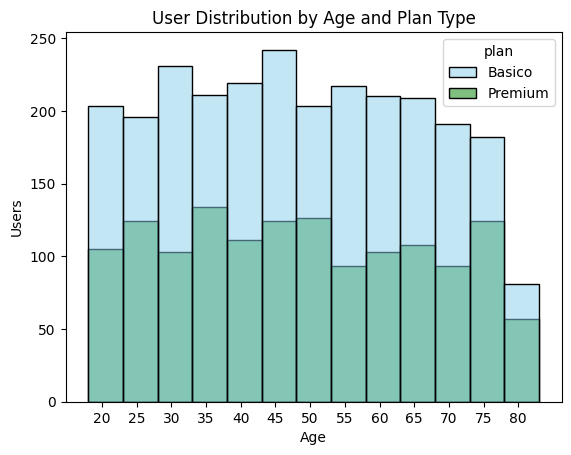

In [37]:
# Histogram of customer age

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    binwidth=5
)
plt.title("User Distribution by Age and Plan Type")
plt.xlabel("Age")
plt.ylabel("Users")
plt.xticks(range(20, 81, 5))
plt.show()


💡 **Insights:**
- The age distribution is relatively uniform, with no clear skew toward older or younger customers, although there is a higher concentration in the 45–50 age range. No evident differences are observed in the age distribution between the `Basico` and `Premium` plans. The higher frequencies in `Basico` are consistent with its larger share of the customer base, close to 65%.


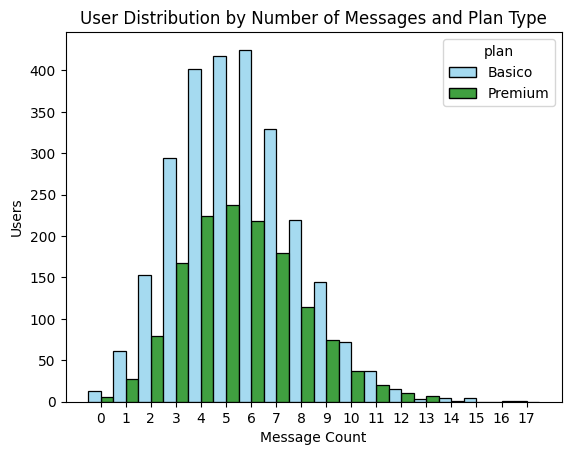

In [38]:
# Histogram of message count

sns.histplot(
    data=user_profile,
    x='msg_cnt',
    hue='plan',
    palette=['skyblue', 'green'],
    multiple='dodge',
    discrete=True
)
plt.title("User Distribution by Number of Messages and Plan Type")
plt.xlabel("Message Count")
plt.ylabel("Users")
plt.xticks(range(0, 18, 1))
plt.show()

💡 **Insights:**
- The highest concentration of customers is between 4 and 6 messages sent.
- The distribution is right-skewed, as the number of customers decreases as the number of messages increases, up to a maximum of 17.
- The `Basico` and `Premium` plans show a similar distribution shape, although `Basico` has higher frequencies because it contains a larger share of customers.


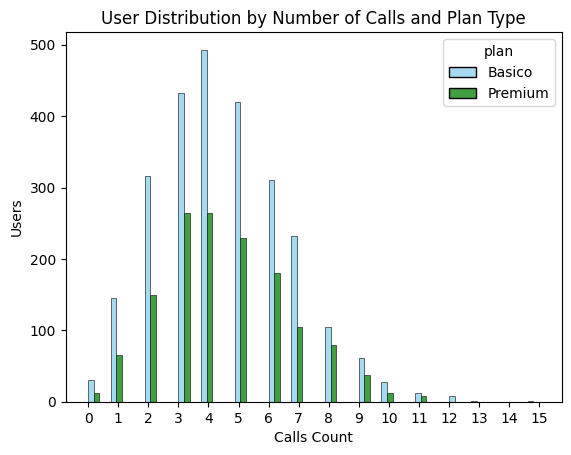

In [39]:
# Histogram of call count
sns.histplot(
    data=user_profile,
    x='call_cnt',
    hue='plan',
    palette=['skyblue', 'green'],
    multiple='dodge'
)

plt.title("User Distribution by Number of Calls and Plan Type")
plt.xlabel("Calls Count")
plt.ylabel("Users")
plt.xticks(range(0, 16, 1))
plt.show()

💡 **Insights:**
- The highest concentration of customers is between 3 and 5 calls.
- The distribution is right-skewed, as the number of customers decreases as the number of calls increases, up to a maximum of 15.
- The `Basico` and `Premium` plans show a similar distribution shape. `Basico` has higher frequencies mainly because it contains a larger share of customers.


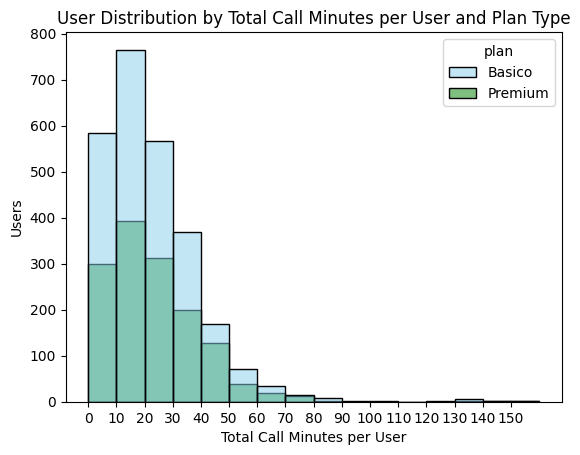

In [40]:
# Histogram of total call minutes
sns.histplot(
    data=user_profile,
    x='call_min',
    hue='plan',
    palette=['skyblue', 'green'],
    binwidth=10
)
plt.title("User Distribution by Total Call Minutes per User and Plan Type")
plt.xlabel("Total Call Minutes per User")
plt.ylabel("Users")
plt.xticks(range(0, 160, 10))
plt.show()

💡 **Insights:**
- 75% of customers accumulate 31.2 total call minutes or less.
- The distribution is right-skewed: most customers accumulate relatively few total call minutes, and the frequency decreases as accumulated time increases, up to a maximum of 155.7 minutes per customer.
- The `Basico` and `Premium` plans show a similar distribution shape. `Basico` has higher frequencies mainly because it contains a larger share of customers.


### 5.2 Outlier Analysis

Boxplots are used to identify extreme values in `age`, `msg_cnt`, `call_cnt`, and `call_min`. For variables with upper-end outliers, IQR thresholds are calculated and compared with observed maxima before deciding whether the values should be retained.


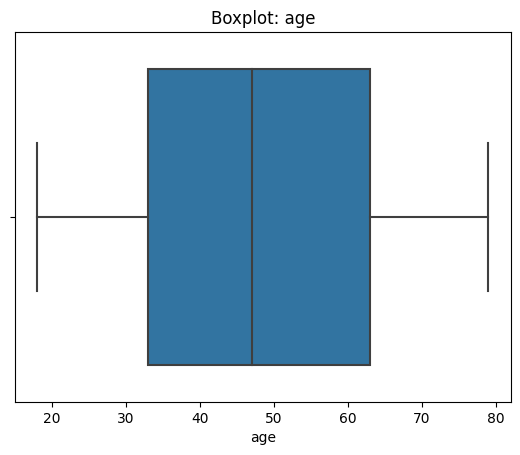

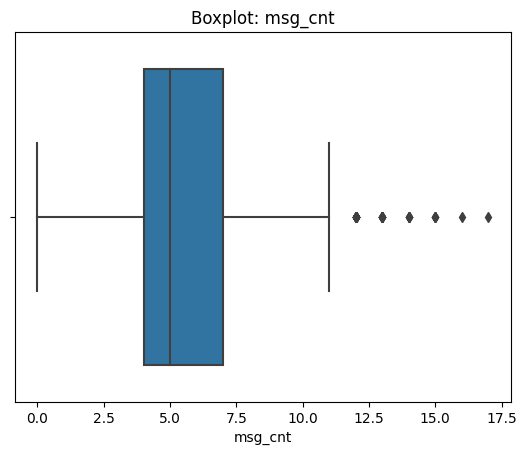

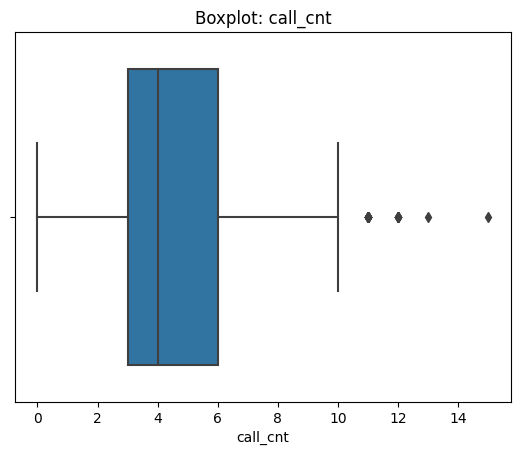

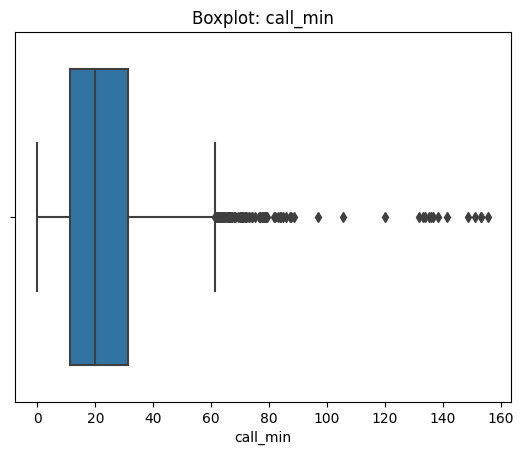

In [41]:
# Visualize distributions using boxplots
numeric_columns = ['age', 'msg_cnt', 'call_cnt', 'call_min']

for col in numeric_columns:
    sns.boxplot(
        data=user_profile,
        x=col,
    )
    plt.title(f'Boxplot: {col}')
    plt.show()

💡 **Insights:**
- `age`: the boxplot does not show outliers.
- `msg_cnt`: the boxplot shows upper-end outliers.
- `call_cnt`: the boxplot shows upper-end outliers.
- `call_min`: the boxplot shows upper-end outliers.


In [42]:

# Calculate upper limits using the IQR method

limit_columns = ['msg_cnt', 'call_cnt', 'call_min']

for col in limit_columns:
    Q1 = user_profile[col].quantile(.25)
    Q3 = user_profile[col].quantile(.75)
    IQR = Q3 - Q1 
    upper_limit = Q3 + (1.5 * IQR)
    print(f'{col}: {upper_limit:.1f}')


msg_cnt: 11.5
call_cnt: 10.5
call_min: 61.3


In [43]:
# Review upper limits and maximum values to decide whether to retain outliers
user_profile[limit_columns].describe()

,msg_cnt,call_cnt,call_min
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.831225
std,2.359738,2.145139,16.592068
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.087500
50%,5.000000,4.000000,19.735000
75%,7.000000,6.000000,31.182500
max,17.000000,15.000000,155.690000


💡 **Insights:**

- `msg_cnt`: the upper limit calculated using IQR is 11.5 messages, so values of 12 or more are considered outliers. The maximum is 17 messages per customer, which is plausible, so these values should be retained.
- `call_cnt`: the upper limit is 10.5 calls, so values of 11 or more are considered outliers. The maximum is 15 calls per customer, which is plausible, so these values should be retained.
- `call_min`: the upper limit is 61.3 accumulated call minutes per customer, and the maximum is 155.7 minutes. Although some values are considerably high, they remain plausible for customers with higher activity, so they should be retained. If necessary, only the visualization should be adjusted to better display the distribution.


---
## 6. Customer Segmentation

### 6.1 Segmentation by Usage Level

Customers are classified according to call and message activity:

- `Low Usage`: fewer than 5 calls and fewer than 5 messages,
- `Medium Usage`: customers not classified as Low Usage who have fewer than 10 calls and fewer than 10 messages,
- `High Usage`: all remaining customers.


In [44]:
# Create the usage_group column
user_profile['usage_group'] = np.where(
    (user_profile['call_cnt'] < 5) & (user_profile['msg_cnt'] < 5), 'Low Usage',
    np.where(
        (user_profile['call_cnt'] < 10) & (user_profile['msg_cnt'] < 10), 'Medium Usage', 'High Usage'),
)

In [45]:
# Verify changes
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,msg_cnt,call_cnt,call_min,usage_group
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Medium Usage
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,High Usage
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Medium Usage
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,High Usage
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Low Usage


In [46]:
# Customers by usage segment
user_profile['usage_group'].value_counts()

Medium Usage    2943
Low Usage        779
High Usage       278
Name: usage_group, dtype: int64

### 6.2 Segmentation by Age

Customers are grouped into three age segments:

- `Young`: under 30,
- `Adult`: 30–59,
- `Older Adult`: 60 or older.


In [47]:
# Create the age_group column
user_profile['age_group'] = np.where(
    user_profile['age'] < 30, 'Young',
    np.where(user_profile['age'] < 60, 'Adult', 'Older Adult')
)

In [48]:
# Verify changes
print("Overview:")
print(user_profile.head())

print()

print("Segmentation:")
print(user_profile[['age', 'msg_cnt', 'call_cnt', 'usage_group', 'age_group']].head())

Overview:
   user_id first_name last_name   age      city                      reg_date  \
0    10000     Carlos    Garcia  38.0  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres  53.0      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez  57.0      CDMX 2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez  69.0    Bogotá 2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres  63.0       GDL 2022-01-02 02:17:11.657914478   

      plan churn_date  msg_cnt  call_cnt  call_min   usage_group    age_group  
0   Basico        NaN      7.0       3.0     23.70  Medium Usage        Adult  
1   Basico        NaN      5.0      10.0     33.18    High Usage        Adult  
2   Basico        NaN      5.0       2.0     10.74  Medium Usage        Adult  
3  Premium        NaN     11.0       3.0      8.99    High Usage  Older Adult  
4   Basico        NaN      4.0       3.0      8.01     Low Usage  Older Adult  

Segmentation:
    age 

In [49]:
# Customers by age group
user_profile['age_group'].value_counts()

Adult          2018
Older Adult    1222
Young           760
Name: age_group, dtype: int64

### 6.3 Segment Distribution

The resulting usage and age segments are visualized and measured as percentages of the customer base.


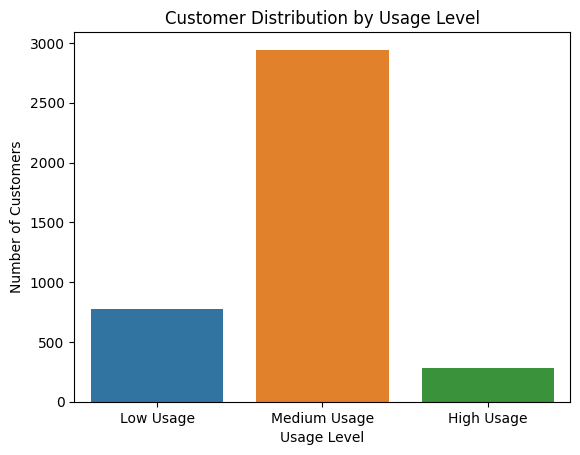

In [50]:
# Visualize usage segments
sns.countplot(
    data=user_profile,
    x='usage_group',
    order=['Low Usage', 'Medium Usage', 'High Usage']
)
plt.title('Customer Distribution by Usage Level')
plt.xlabel('Usage Level')
plt.ylabel('Number of Customers')
plt.show()

In [51]:
# Percentage of customers by usage level
user_profile['usage_group'].value_counts(normalize=True) * 100

Medium Usage    73.575
Low Usage       19.475
High Usage       6.950
Name: usage_group, dtype: float64

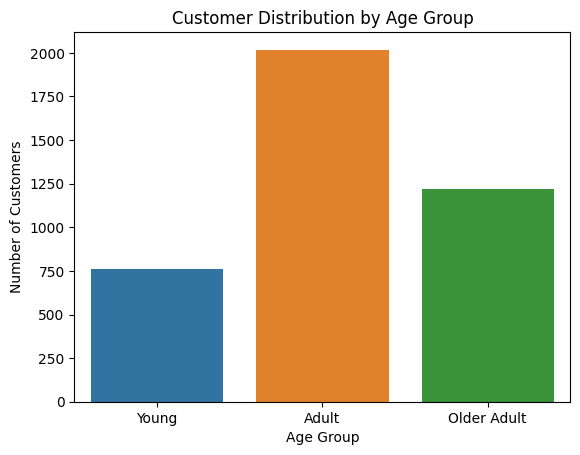

In [52]:
# Visualize age segments
sns.countplot(
    data=user_profile,
    x='age_group',
    order=['Young', 'Adult', 'Older Adult']
)
plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.show()

In [53]:
# Percentage of customers by age group
user_profile['age_group'].value_counts(normalize=True) * 100

Adult          50.45
Older Adult    30.55
Young          19.00
Name: age_group, dtype: float64

---
## 7. Business Findings for Stakeholders

### Data Quality Findings

- The `users` table contained missing values in `city` and `churn_date`, representing approximately **11.7%** and **88.4%** of records, respectively.
- `city` also contained the sentinel value `"?"` in **96 records (2.4%)**, which was replaced with missing values.
- `age` contained the sentinel value `-999`, which was replaced with the median age.
- `reg_date` contained **40 records (1.0%)** from 2026, outside the expected reporting period through 2024; these dates were marked as missing.
- The `usage` table contained missing values in `date`, `duration`, and `length`, representing approximately **0.1%**, **55.2%**, and **44.7%** of records.
- Missing `duration` and `length` values are largely explained by interaction type and were retained when the field did not apply to that interaction.
- Suspicious cross-field values were also observed, including `text` records with `duration = 120` and `call` records with `length = 1490`.
- One customer had no records in `usage`. A left merge preserved all **4,000 customers**, and that customer's usage metrics were set to zero.

### Customer Segments

**By usage level**

- `Medium Usage`: **73.6%**
- `Low Usage`: **19.5%**
- `High Usage`: **7.0%**

**By age**

- `Adult` (30–59): **50.5%**
- `Older Adult` (60+): **30.6%**
- `Young` (<30): **19.0%**

The customer base is therefore concentrated mainly among customers aged 30 or older and within the `Medium Usage` segment.

### Plan Distribution

- `Basico`: approximately **64.9%** of customers.
- `Premium`: approximately **35.1%** of customers.
- Age, message, call, and accumulated-minute distributions show broadly similar shapes across both plans.
- The higher absolute frequencies observed for `Basico` are consistent with its larger customer base.

The size of the `Basico` base makes it especially relevant for retention, increased engagement, and selective migration to higher-value offers. The smaller `Premium` base represents an opportunity to expand adoption through differentiated benefits and promotions.

### Outlier Findings

Upper-end outliers were identified in the main usage variables:

- `msg_cnt`: IQR upper threshold **11.5**; values of 12+ are outliers; maximum **17**.
- `call_cnt`: IQR upper threshold **10.5**; values of 11+ are outliers; maximum **15**.
- `call_min`: IQR upper threshold approximately **61.3 accumulated minutes**; maximum **155.7**.

These extreme values remain plausible for highly active customers and are retained. Commercially, such customers may be relevant for loyalty programs and offers aimed at higher usage levels.

### Commercial Recommendations

- Prioritize retention and increased engagement among `Medium Usage` customers, who represent nearly three-quarters of the customer base.
- Capitalize on the large `Basico` customer base through retention initiatives, greater service usage, and selective migration to higher-value offers.
- Strengthen `Premium` adoption through differentiated benefits, promotions, and a clearer value proposition.
- Develop loyalty initiatives for `High Usage` customers.
- Address `Low Usage` customers with engagement initiatives designed to reduce potential churn.
- Maintain a competitive value proposition for the `Adult` segment, which represents roughly half of the customer base.
- Strengthen the offer for `Young` customers to increase their representation within the customer base.


---
## 8. Executive Summary

ConnectaTel's customer base is predominantly **adult**, concentrated in the **Medium Usage** segment, and primarily subscribed to the **Basico** plan.

The strongest near-term commercial opportunity lies in the large `Medium Usage` and `Basico` customer bases. Their size supports prioritizing retention, deeper engagement, and selective migration to higher-value offers. `Premium`, which represents approximately one-third of customers, offers additional growth potential through differentiated benefits and targeted promotions.

`High Usage` customers form a smaller but strategically relevant segment for loyalty initiatives, while `Low Usage` customers warrant engagement actions aimed at strengthening service use and reducing potential churn. The lower representation of `Young` customers also suggests room to strengthen the value proposition for this segment.

### Recommended Priorities

1. **Retain and deepen engagement** among `Medium Usage` customers.
2. **Monetize the scale of `Basico`** through usage growth and selective upgrades.
3. **Grow `Premium` adoption** through differentiated benefits and targeted promotions.
4. **Protect high-value engagement** with loyalty initiatives for `High Usage` customers.
5. **Reduce disengagement risk** among `Low Usage` customers.
6. **Strengthen the proposition for younger customers** to increase their participation in the customer base.
